# Atividade Prática de NLP – Classificação de Fake News (corpus Fake.br)
**RU: 4957311**

Pipeline: aquisição → estruturação → pré-processamento (NLTK) → balanceamento → divisão treino/teste → TF-IDF (1 a 3-gramas) → modelo → nuvens de palavras.

In [1]:
import re
import random
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import RegexpTokenizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from wordcloud import WordCloud
from PIL import Image, ImageDraw

nltk.download("stopwords", quiet=True)

True

## Identificação pessoal (RU)

In [2]:
RU = "4957311"
contador4957311 = 0  # identificador pessoal (variável com o RU no nome)
SEED = 42

## 1. Aquisição e estruturação

In [3]:
df = pd.read_csv("pre-processed.csv", encoding="utf-8")
df = df[["label", "preprocessed_news"]].rename(columns={"preprocessed_news": "texto"})
df["label"] = df["label"].map({"fake": "FAKE", "true": "REAL"})
df = df.dropna(subset=["texto"]).reset_index(drop=True)

print("Formato:", df.shape)
print(df["label"].value_counts())
df.head(3)

Formato: (7200, 2)
label
FAKE    3600
REAL    3600
Name: count, dtype: int64


,label,texto
0,FAKE,katia abreu diz vai colocar expulsao moldura n...
1,FAKE,ray peita bolsonaro conservador fake entrevist...
2,FAKE,reinaldo azevedo desmascarado policia federal ...


## 2. Pré-processamento com NLTK
minúsculas, remoção de acentos, tokenização (NLTK), remoção de stopwords (NLTK) e de tokens de 1 letra.

In [4]:
def remover_acentos(s):
    return "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))

stop_pt = {remover_acentos(w) for w in stopwords.words("portuguese")}
tokenizador = RegexpTokenizer(r"[a-z]+")

def preprocessar(texto):
    texto = remover_acentos(str(texto).lower())
    tokens = tokenizador.tokenize(texto)
    return [t for t in tokens if t not in stop_pt and len(t) > 1]

df["tokens"] = df["texto"].apply(preprocessar)
df["n_tokens"] = df["tokens"].str.len()
print(df.groupby("label")["n_tokens"].agg(["count", "mean", "sum"]))

       count        mean      sum
label                            
FAKE    3600  102.611667   369402
REAL    3600  594.999444  2141998


## 3. Balanceamento da quantidade de palavras (FAKE x REAL)
Os textos REAL são truncados em um limite fixo de tokens, escolhido para que o total de palavras de REAL fique igual ao total de FAKE.

In [5]:
alvo = int(df.loc[df["label"] == "FAKE", "n_tokens"].sum())
tam_real = df.loc[df["label"] == "REAL", "n_tokens"]

lo, hi = 1, int(tam_real.max())
while lo < hi:
    meio = (lo + hi) // 2
    if tam_real.clip(upper=meio).sum() < alvo:
        lo = meio + 1
    else:
        hi = meio
limite = lo

df["tokens_norm"] = [t[:limite] if l == "REAL" else t for t, l in zip(df["tokens"], df["label"])]
df["texto_norm"] = df["tokens_norm"].apply(" ".join)
df["n_tokens_norm"] = df["tokens_norm"].str.len()

print("Limite de tokens por texto REAL:", limite)
print(df.groupby("label")["n_tokens_norm"].sum())

Limite de tokens por texto REAL: 103
label
FAKE    369402
REAL    369973
Name: n_tokens_norm, dtype: int64


## 4. Divisão treino (75%) / teste (25%), estratificada

In [6]:
X_treino_txt, X_teste_txt, y_treino, y_teste = train_test_split(
    df["texto_norm"], df["label"], test_size=0.25, stratify=df["label"], random_state=SEED
)
print(len(X_treino_txt), "treino |", len(X_teste_txt), "teste")
print(y_treino.value_counts().to_dict(), y_teste.value_counts().to_dict())

5400 treino | 1800 teste
{'REAL': 2700, 'FAKE': 2700} {'REAL': 900, 'FAKE': 900}


## 5. TF-IDF (unigramas, bigramas e trigramas) e modelo (SVM linear)

In [7]:
vetorizador = TfidfVectorizer(ngram_range=(1, 3), min_df=3, max_df=0.9, sublinear_tf=True)
X_treino = vetorizador.fit_transform(X_treino_txt)
X_teste = vetorizador.transform(X_teste_txt)
print("Matriz de treino:", X_treino.shape)

modelo = LinearSVC(random_state=SEED)
modelo.fit(X_treino, y_treino)

pred = modelo.predict(X_teste)
acuracia = accuracy_score(y_teste, pred)
print(f"ACURÁCIA: {acuracia:.4f} ({acuracia*100:.2f}%)  | RU: {RU}")
print(classification_report(y_teste, pred))
print(confusion_matrix(y_teste, pred, labels=["REAL", "FAKE"]))

Matriz de treino: (5400, 40208)
ACURÁCIA: 0.9128 (91.28%)  | RU: 4957311
              precision    recall  f1-score   support

        FAKE       0.92      0.91      0.91       900
        REAL       0.91      0.92      0.91       900

    accuracy                           0.91      1800
   macro avg       0.91      0.91      0.91      1800
weighted avg       0.91      0.91      0.91      1800

[[826  74]
 [ 83 817]]


## 6. Quantidade de termos usados por rótulo (treino)

In [8]:
termos = np.array(vetorizador.get_feature_names_out())
n_gram = np.array([t.count(" ") + 1 for t in termos])
y_arr = y_treino.to_numpy()

def termos_da_classe(rotulo):
    X_cl = X_treino[y_arr == rotulo]
    soma = np.asarray(X_cl.sum(axis=0)).ravel()
    media = np.asarray(X_cl.mean(axis=0)).ravel()
    return soma > 0, media

resumo = {}
for rotulo in ["REAL", "FAKE"]:
    presente, media = termos_da_classe(rotulo)
    resumo[rotulo] = {
        "total": int(presente.sum()),
        "palavras": int((presente & (n_gram == 1)).sum()),
        "bigramas": int((presente & (n_gram == 2)).sum()),
        "trigramas": int((presente & (n_gram == 3)).sum()),
        "media": media,
        "presente": presente,
    }
    r = resumo[rotulo]
    print(f"{rotulo}: {r['total']} termos = {r['palavras']} palavras + {r['bigramas']} bigramas + {r['trigramas']} trigramas")

REAL: 34864 termos = 14642 palavras + 15918 bigramas + 4304 trigramas
FAKE: 34494 termos = 15080 palavras + 15749 bigramas + 3665 trigramas


## 7. Nuvens de palavras (tamanho = peso TF-IDF médio na classe)

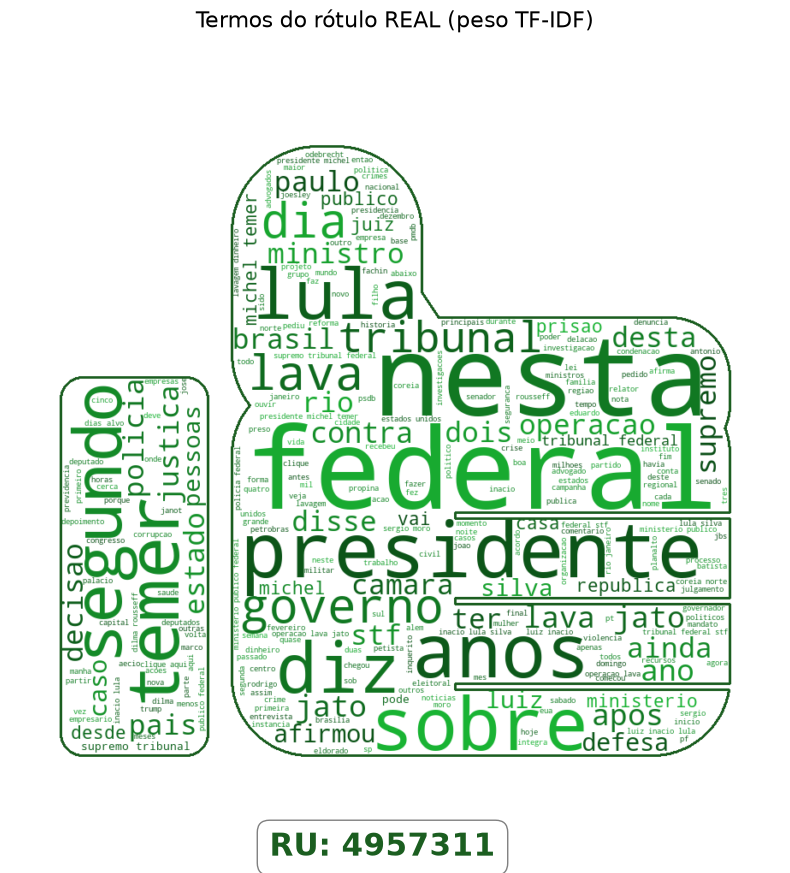

In [9]:
def mascara_polegar(cima=True, tam=900):
    """Desenha a silhueta de um polegar (para cima = REAL, para baixo = FAKE)."""
    img = Image.new("L", (tam, tam), 255)
    d = ImageDraw.Draw(img)
    s = tam / 900
    def r(x0, y0, x1, y1, raio):
        d.rounded_rectangle([x0*s, y0*s, x1*s, y1*s], radius=raio*s, fill=0)
    r(60, 400, 230, 840, 25)      # manga
    r(260, 400, 840, 840, 90)     # palma e dedos
    r(260, 130, 480, 470, 100)    # polegar
    r(380, 330, 840, 500, 70)     # ligação
    d.polygon([(300*s, 400*s), (480*s, 300*s), (560*s, 420*s), (300*s, 470*s)], fill=0)
    for y in (560, 660, 760):     # separação dos dedos
        d.line([(520*s, y*s), (840*s, y*s)], fill=255, width=int(8*s))
    arr = np.array(img)
    return arr if cima else np.flipud(arr)

def gerar_nuvem(rotulo, matiz, titulo, arquivo, top=400):
    r = resumo[rotulo]
    pesos = np.where(r["presente"], r["media"], 0)
    idx = np.argsort(pesos)[::-1][:top]
    freq = {termos[i]: float(pesos[i]) for i in idx if pesos[i] > 0}

    def cor(*args, **kwargs):
        return f"hsl({matiz}, 75%, {random.randint(18, 40)}%)"

    mascara = mascara_polegar(cima=(rotulo == "REAL"))
    nuvem = WordCloud(background_color="white", mask=mascara, color_func=cor,
                      max_words=top, prefer_horizontal=0.9, min_font_size=6,
                      contour_width=3, contour_color="#1b5e20" if rotulo == "REAL" else "#b71c1c",
                      random_state=SEED).generate_from_frequencies(freq)

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(nuvem.to_array(), interpolation="bilinear")
    ax.axis("off")
    ax.set_title(titulo, fontsize=16)
    fig.text(0.5, 0.06, f"RU: {RU}", ha="center", fontsize=22, fontweight="bold",
             color="#1b5e20" if rotulo == "REAL" else "#b71c1c",
             bbox=dict(facecolor="white", edgecolor="gray", boxstyle="round,pad=0.4"))
    fig.savefig(arquivo, dpi=150, bbox_inches="tight")
    plt.show()
    return freq

freq_real = gerar_nuvem("REAL", 130, "Termos do rótulo REAL (peso TF-IDF)", f"nuvem_real_{RU}.png")

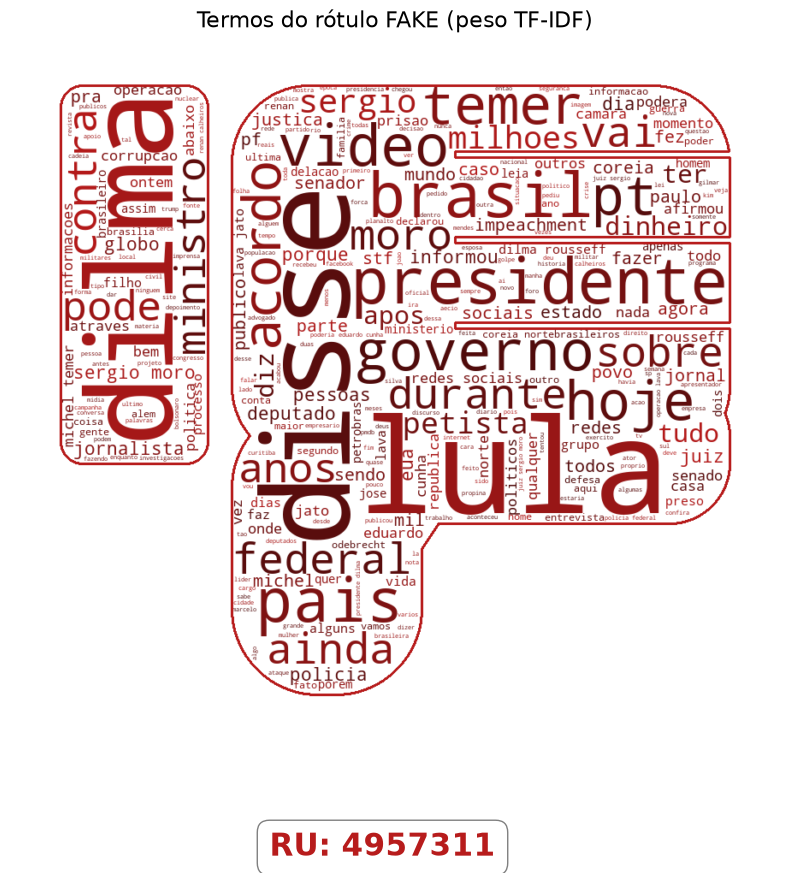

In [10]:
freq_fake = gerar_nuvem("FAKE", 0, "Termos do rótulo FAKE (peso TF-IDF)", f"nuvem_fake_{RU}.png")

In [11]:
print("Top 15 REAL:", list(freq_real)[:15])
print("Top 15 FAKE:", list(freq_fake)[:15])

Top 15 REAL: ['federal', 'nesta', 'presidente', 'anos', 'sobre', 'temer', 'lula', 'diz', 'segundo', 'governo', 'lava', 'dia', 'tribunal', 'lava jato', 'jato']
Top 15 FAKE: ['lula', 'disse', 'dilma', 'presidente', 'brasil', 'pais', 'video', 'governo', 'temer', 'pt', 'hoje', 'acordo', 'durante', 'sobre', 'federal']


## 8. Respostas

In [12]:
print(f"[Q1] REAL: {resumo['REAL']['total']} termos "
      f"({resumo['REAL']['palavras']} palavras, {resumo['REAL']['bigramas']} bigramas, {resumo['REAL']['trigramas']} trigramas). "
      f"Acurácia: {acuracia*100:.2f}%")
print(f"[Q2] FAKE: {resumo['FAKE']['total']} termos "
      f"({resumo['FAKE']['palavras']} palavras, {resumo['FAKE']['bigramas']} bigramas, {resumo['FAKE']['trigramas']} trigramas).")
print("Técnicas: minúsculas, remoção de acentos, tokenização NLTK, stopwords NLTK, truncamento p/ balancear, TF-IDF 1-3 gramas.")
print("Modelo: LinearSVC (SVM linear).")

[Q1] REAL: 34864 termos (14642 palavras, 15918 bigramas, 4304 trigramas). Acurácia: 91.28%
[Q2] FAKE: 34494 termos (15080 palavras, 15749 bigramas, 3665 trigramas).
Técnicas: minúsculas, remoção de acentos, tokenização NLTK, stopwords NLTK, truncamento p/ balancear, TF-IDF 1-3 gramas.
Modelo: LinearSVC (SVM linear).
